# Tomato Leaf Disease Classification: MobileNetV2 Transfer Learning

This notebook trains and evaluates a classifier that reads a tomato leaf photo and returns one of four labels: **Early blight, Late blight, Leaf mold or Healthy**. It covers training, evaluation on the held-out test set, the results overall and for each class, and a Grad-CAM explanation of the model's decisions.

**Data.** PlantVillage tomato leaves (Kaggle, colour version). Four classes, each capped at 900 photos so the classes are balanced.

**Model.** MobileNetV2 pretrained on ImageNet. The pretrained base is **frozen** (feature extraction); only the classifier head is trained. The head is: global average pooling, dropout, a dense layer, dropout, and a softmax over the four classes.

**Loss.** Class-weighted categorical cross-entropy. The weights come from the class counts; with balanced classes they equal 1.

### Training configuration (one run, no search)
| Setting | Value |
|---|---|
| Epochs (maximum) | 30 |
| Optimizer and learning rate | Adam, 0.001 |
| Dropout | 0.3 |
| Early stopping | watches validation loss, min_delta 0.002, patience 5, restores the best weights |
| Learning-rate reduction | on plateau of validation loss, factor 0.5, patience 3 |
| Checkpoint | the epoch with the lowest validation loss is saved |
| Logging | TensorBoard (Keras callback), and the per-epoch precision, recall, F1 score and ROC AUC printed below |

### What is in this notebook
1. Settings and environment (Colab, Kaggle or local)
2. Functions used by the training (copied from `src/`, so the training code is all here)
3. Data: the train / validation / test split and a duplicate check
4. Exploration of the photos
5. Datasets and class weights
6. The model
7. Training with callbacks and per-epoch metrics
8. Training curves
9. Results on the test set: overall, per class, confusion matrices and ROC curves
10. Grad-CAM explanations for 12 test photos
11. Saving the model and the results

The web application (in `src/`) uses the same preprocessing, model and metric functions. It also retrains the model on uploaded photos. Retraining, the upload database and the demo are not part of this notebook.

### Running it: Colab, Kaggle or your own machine
The notebook detects where it runs and sets the paths itself.

| | Colab | Kaggle | Local |
|---|---|---|---|
| Dataset | downloaded from Kaggle with the token in Colab Secrets | attach **plant-village** (arjuntejaswi/plant-village) to the notebook | place the four class folders in `notebook_work/raw/` |
| Outputs (models, results, TensorBoard logs) | Google Drive, `tomato_leaf_project/` | `/kaggle/working/outputs/` (Output tab) | `notebook_work/` |
| Settings | GPU runtime | **Accelerator: GPU** and **Internet: On** (the ImageNet weights download on first use) | any; GPU optional |

In [1]:
import os, sys, io, json, random, shutil, hashlib, subprocess, glob
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as colour_maps
import seaborn as sns
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow.keras import layers, regularizers
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, auc,
                             precision_recall_fscore_support, roc_auc_score)

tf.keras.utils.set_random_seed(42)      # seeds Python, NumPy and TensorFlow
sns.set_style("whitegrid")
print("TensorFlow", tf.__version__, "| GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow 2.21.0 | GPU available: True


In [2]:
# ---- Environment detection: Colab, Kaggle or a local run ----
# Kaggle sets KAGGLE_KERNEL_RUN_TYPE and provides /kaggle/working. Colab has google.colab. Anything else is local.
# The two overrides are for testing only; leave them unset on Colab, Kaggle and your own machine.
KAGGLE_INPUT = os.environ.get("KAGGLE_INPUT_DIR", "/kaggle/input")
KAGGLE_WORKING = os.environ.get("KAGGLE_WORKING_DIR", "/kaggle/working")
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE")) or os.path.isdir(KAGGLE_WORKING)
ENVIRONMENT = "colab" if IN_COLAB else ("kaggle" if IN_KAGGLE else "local")
print("environment:", ENVIRONMENT)

def internet_available(url="https://storage.googleapis.com", timeout=5):
    import urllib.request
    try:
        urllib.request.urlopen(url, timeout=timeout)
        return True
    except Exception:
        return False

if ENVIRONMENT == "colab":
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    WORK_DIR = "/content/work"                                  # local disk: much faster than Drive
    DRIVE_DIR = "/content/drive/MyDrive/tomato_leaf_project"    # models and results survive a session reset
elif ENVIRONMENT == "kaggle":
    WORK_DIR = f"{KAGGLE_WORKING}/tomato"                       # /kaggle/working is kept as the notebook output
    DRIVE_DIR = f"{KAGGLE_WORKING}/outputs"                     # models and results: download them from the Output tab
    if not internet_available():
        print("WARNING: no internet. MobileNetV2 ImageNet weights are downloaded on first use, so turn Settings > "
              "Internet on, or attach a dataset that already holds the weights.")
else:                                                           # local run
    WORK_DIR = os.path.join(os.getcwd(), "notebook_work")
    DRIVE_DIR = WORK_DIR

RAW_DIR = f"{WORK_DIR}/raw"
MODEL_DIR = f"{DRIVE_DIR}/models"
RESULTS_DIR = f"{DRIVE_DIR}/results"
for d in (MODEL_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
print("work:", WORK_DIR, "| models:", MODEL_DIR)

environment: colab
Mounted at /content/drive
work: /content/work | models: /content/drive/MyDrive/tomato_leaf_project/models


In [3]:
# ---- Training settings: every value that the training uses is written here ----
EPOCHS = 30                        # maximum number of epochs; early stopping may end the run sooner
LEARNING_RATE = 0.001              # Adam learning rate for the classifier head
DROPOUT_RATE = 0.3                 # dropout after the pooling layer and after the hidden dense layer
HIDDEN_UNITS = 128                 # size of the hidden dense layer
L2_STRENGTH = 1e-4                 # L2 weight decay on both dense layers
EARLY_STOPPING_MIN_DELTA = 0.002   # validation loss must drop by at least this much to count as an improvement
EARLY_STOPPING_PATIENCE = 5        # epochs without improvement before training stops
REDUCE_LR_FACTOR = 0.5             # when validation loss plateaus, the learning rate is multiplied by this
REDUCE_LR_PATIENCE = 3             # epochs without improvement before the learning rate is reduced
MINIMUM_LEARNING_RATE = 1e-6
PHOTOS_PER_CLASS = 900             # cap per class (the smallest class has 952 photos)
TEST_FRACTION = 0.2                # share of the photos kept for the test set
VALIDATION_FRACTION = 0.2          # share of the training photos used for validation
IMG_SIZE = (224, 224)              # MobileNetV2 input size
BATCH_SIZE = 32
RANDOM_SEED = 42
GRADCAM_PHOTOS_PER_CLASS = 3       # 4 classes x 3 photos = 12 test photos explained with Grad-CAM
print("settings: epochs", EPOCHS, "| learning rate", LEARNING_RATE, "| dropout", DROPOUT_RATE)

settings: epochs 30 | learning rate 0.001 | dropout 0.3


## 2. Functions used by the training

These functions are copied from the shared code in `src/`, so the notebook contains every function that the training uses. The web application imports the same code.

### Functions: preprocessing
Decoding and resizing, the hash-based train/validation split, the `tf.data` pipelines and the augmentation. The dashboard statistics at the end of `src/preprocessing.py` are not needed for training and are left out.

In [4]:
"""Preprocessing shared by the training notebook, the web app and the retraining code.

Training and serving use the SAME TensorFlow operations (decode -> float -> bilinear resize to 224 x 224),
so a photo gives the same model input whether it comes from a training folder or an upload.
Pixels stay in the 0-255 range here; the first layer of the model maps them to [-1, 1] for MobileNetV2.

The train/validation split is decided by a hash of each file's relative path, not by a random shuffle.
A file therefore always lands in the same subset, and new uploads never move existing images.
"""
import hashlib
import io
import os

import numpy as np
import tensorflow as tf
from PIL import Image

IMG_SIZE = (224, 224)                  # MobileNetV2's native input size
INSIGHT_SIZE = (128, 128)              # size used only for the dashboard colour and brightness statistics
BATCH_SIZE = 32
VALIDATION_FRACTION = 0.2
RANDOM_SEED = 42
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")
AUTOTUNE = tf.data.AUTOTUNE


# ---------- decoding (shared by training and serving) ----------

def decode_and_resize(image_bytes, image_size=IMG_SIZE):
    """Decode image bytes (a scalar string tensor) and return a float32 tensor of shape (H, W, 3), values 0-255."""
    decoded = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    resized = tf.image.resize(tf.cast(decoded, tf.float32), image_size, method="bilinear")
    resized.set_shape((image_size[0], image_size[1], 3))
    return resized


def preprocess_bytes(image_bytes):
    """Prepare ONE photo given as bytes for prediction. Returns a float32 array of shape (1, 224, 224, 3)."""
    try:
        model_input = decode_and_resize(tf.constant(image_bytes))
    except tf.errors.InvalidArgumentError:
        # a format TensorFlow cannot decode (for example TIFF): decode with Pillow and re-encode losslessly as PNG
        buffer = io.BytesIO()
        Image.open(io.BytesIO(image_bytes)).convert("RGB").save(buffer, "PNG")
        model_input = decode_and_resize(tf.constant(buffer.getvalue()))
    return model_input.numpy()[None, ...]


def preprocess_path(image_path):
    with open(image_path, "rb") as image_file:
        return preprocess_bytes(image_file.read())


# ---------- file lists and the train / validation split ----------

def list_image_files(folder):
    return sorted(os.path.join(folder, name) for name in os.listdir(folder) if name.lower().endswith(IMAGE_EXTENSIONS))


def labelled_items(root_folder, class_names):
    """Return (image_path, class_index) for every photo in root_folder/<class_name>/. Missing class folders are skipped."""
    items = []
    for class_index, class_name in enumerate(class_names):
        class_folder = os.path.join(root_folder, class_name)
        if os.path.isdir(class_folder):
            items.extend((image_path, class_index) for image_path in list_image_files(class_folder))
    return items


def _hash_bucket(text):
    """A number between 0 and 1 that depends only on the text, so the same file always gets the same number."""
    return int(hashlib.md5(text.encode("utf-8")).hexdigest()[:8], 16) / 0xFFFFFFFF


def split_train_validation(items, root_folder, validation_fraction=VALIDATION_FRACTION):
    """Deterministic train/validation split. The key is the path relative to root_folder, so it never changes."""
    training_items, validation_items = [], []
    for image_path, class_index in items:
        relative_path = os.path.relpath(image_path, root_folder).replace("\\", "/")
        target = validation_items if _hash_bucket(relative_path) < validation_fraction else training_items
        target.append((image_path, class_index))
    return training_items, validation_items


def count_per_class(items, number_of_classes):
    counts = np.zeros(number_of_classes, dtype=int)
    for _, class_index in items:
        counts[class_index] += 1
    return counts


# ---------- tf.data pipelines ----------

_augmentation_layers = None


def get_augmentation():
    """Random flips, rotation, zoom and brightness, applied to training photos only."""
    global _augmentation_layers
    if _augmentation_layers is None:
        from tensorflow.keras import layers
        _augmentation_layers = tf.keras.Sequential([
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
            layers.RandomBrightness(0.2, value_range=(0, 255)),
        ], name="augmentation")
    return _augmentation_layers


def make_dataset(items, number_of_classes, shuffle=False, augment=False, batch_size=BATCH_SIZE, seed=RANDOM_SEED):
    """Batches of (images, one-hot labels). The order is kept unless shuffle=True."""
    image_paths = [image_path for image_path, _ in items]
    class_indices = [class_index for _, class_index in items]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, class_indices))
    if shuffle:
        dataset = dataset.shuffle(len(items), seed=seed, reshuffle_each_iteration=True)
    dataset = dataset.map(
        lambda image_path, class_index: (decode_and_resize(tf.io.read_file(image_path)),
                                         tf.one_hot(class_index, number_of_classes)),
        num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(batch_size)
    if augment:
        augmentation = get_augmentation()
        dataset = dataset.map(lambda images, labels: (augmentation(images, training=True), labels),
                              num_parallel_calls=AUTOTUNE)
    return dataset.prefetch(AUTOTUNE)

### Functions: model, class weights, weighted loss, metrics and per-epoch reporting
The MobileNetV2 model with a frozen base and a trainable head, the class-weight calculation, the weighted categorical cross-entropy, the overall and per-class metrics, and the callback that measures precision, recall, F1 score and ROC AUC after every epoch. The settings used here are in the Training settings cell.

In [5]:
"""Model, class weights, weighted loss, metrics and per-epoch reporting.

Model: MobileNetV2 pretrained on ImageNet, with the base FROZEN (feature extraction).
Only the classifier head is trained:
    global average pooling -> dropout -> dense (hidden units, L2) -> dropout -> dense (classes, softmax, L2).
Loss: class-weighted categorical cross-entropy (weights are inverse class frequencies, normalised to mean 1).
"""
import numpy as np
import tensorflow as tf
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score
from tensorflow.keras import layers, regularizers


BASE_MODEL_NAME = "mobilenetv2_base"
CLASSIFIER_NAME = "tomato_mobilenetv2"


# ---------- class weights and loss ----------

def balanced_class_weights(class_counts):
    """Inverse-frequency weights scaled so that their mean is 1. Equal class sizes give a weight of 1 everywhere."""
    class_counts = np.asarray(class_counts, dtype=np.float64)
    number_of_classes = len(class_counts)
    raw_weights = class_counts.sum() / (number_of_classes * np.maximum(class_counts, 1))
    return (raw_weights / raw_weights.mean()).tolist()


def weighted_categorical_crossentropy(class_weights):
    """Categorical cross-entropy where every photo's loss is multiplied by the weight of its true class."""
    weight_tensor = tf.constant(class_weights, dtype=tf.float32)

    def loss(true_one_hot, predicted_probabilities):
        predicted_probabilities = tf.clip_by_value(predicted_probabilities, 1e-7, 1.0 - 1e-7)
        cross_entropy = -tf.reduce_sum(true_one_hot * tf.math.log(predicted_probabilities), axis=-1)
        photo_weight = tf.reduce_sum(true_one_hot * weight_tensor, axis=-1)
        return photo_weight * cross_entropy

    loss.__name__ = "weighted_categorical_crossentropy"
    return loss


# ---------- model ----------

def build_model(number_of_classes, dropout_rate=0.5, l2_strength=1e-4, learning_rate=1e-3,
                class_weights=None, hidden_units=128):
    base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False,
                                                   weights="imagenet", name=BASE_MODEL_NAME)
    base_model.trainable = False
    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(1 / 127.5, offset=-1)(inputs)      # MobileNetV2 expects pixels in [-1, 1]
    x = base_model(x, training=False)                        # BatchNorm stays in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(hidden_units, activation="relu", kernel_initializer="he_normal",
                     kernel_regularizer=regularizers.l2(l2_strength))(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(number_of_classes, activation="softmax",
                           kernel_regularizer=regularizers.l2(l2_strength))(x)
    model = tf.keras.Model(inputs, outputs, name=CLASSIFIER_NAME)
    compile_model(model, learning_rate=learning_rate, class_weights=class_weights)
    return model


def compile_model(model, learning_rate=1e-3, class_weights=None):
    if class_weights is None:
        class_weights = [1.0] * model.output_shape[-1]
    model.get_layer(BASE_MODEL_NAME).trainable = False      # the pretrained base is never trained
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss=weighted_categorical_crossentropy(class_weights),
                  metrics=["accuracy"])
    return model


def load_trained(model_path):
    """Load a saved model for inference or fine-tuning. The loss is rebuilt by compile_model."""
    return tf.keras.models.load_model(model_path, compile=False)


# ---------- metrics ----------

def compute_metrics(true_labels, predicted_probabilities, class_weights):
    """Overall metrics: accuracy, weighted loss, macro precision, macro recall, macro F1 and macro one-vs-rest ROC AUC.

    The loss is computed from the predicted probabilities, so it does not include the L2 penalty that
    model.evaluate() adds. Macro averages give every class the same weight, so a weak class cannot hide.
    """
    true_labels = np.asarray(true_labels)
    predicted_probabilities = np.asarray(predicted_probabilities, dtype=np.float64)
    number_of_classes = predicted_probabilities.shape[1]
    predicted_labels = predicted_probabilities.argmax(axis=1)
    clipped = np.clip(predicted_probabilities, 1e-7, 1 - 1e-7)
    cross_entropy = -np.log(clipped[np.arange(len(true_labels)), true_labels])
    loss = float((np.asarray(class_weights)[true_labels] * cross_entropy).mean())
    precision, recall, f1_score, _ = precision_recall_fscore_support(
        true_labels, predicted_labels, average="macro", labels=list(range(number_of_classes)), zero_division=0)
    try:
        roc_auc = float(roc_auc_score(true_labels, predicted_probabilities, multi_class="ovr",
                                      average="macro", labels=list(range(number_of_classes))))
    except ValueError:      # a class missing from the true labels makes ROC AUC undefined; None keeps JSON valid
        roc_auc = None
    return {"accuracy": float((predicted_labels == true_labels).mean()), "loss": loss,
            "precision": float(precision), "recall": float(recall), "f1": float(f1_score), "roc_auc": roc_auc}


def compute_per_class_metrics(true_labels, predicted_probabilities, class_names):
    """One row per class: precision, recall, F1 score, number of test photos, and one-vs-rest ROC AUC."""
    true_labels = np.asarray(true_labels)
    predicted_probabilities = np.asarray(predicted_probabilities)
    predicted_labels = predicted_probabilities.argmax(axis=1)
    number_of_classes = len(class_names)
    precision, recall, f1_score, support = precision_recall_fscore_support(
        true_labels, predicted_labels, labels=list(range(number_of_classes)), zero_division=0)
    rows = []
    for class_index, class_name in enumerate(class_names):
        is_this_class = (true_labels == class_index).astype(int)
        try:
            class_roc_auc = float(roc_auc_score(is_this_class, predicted_probabilities[:, class_index]))
        except ValueError:
            class_roc_auc = None
        rows.append({"class": class_name, "precision": float(precision[class_index]),
                     "recall": float(recall[class_index]), "f1_score": float(f1_score[class_index]),
                     "test_photos": int(support[class_index]), "roc_auc": class_roc_auc})
    return rows


def evaluate_dataset(model, dataset, true_labels, class_weights):
    """Predict an unshuffled dataset and compute compute_metrics. true_labels must follow the dataset order."""
    predicted_probabilities = model.predict(dataset, verbose=0)
    return compute_metrics(true_labels, predicted_probabilities, class_weights)


# ---------- per-epoch reporting ----------

def _text(value):
    return "    n/a" if value is None else f"{value:.3f}"


class EpochMetrics(tf.keras.callbacks.Callback):
    """After every epoch, measures precision, recall, F1 score and ROC AUC on the training photos (no augmentation,
    inference mode) and on the validation photos, and also records the Keras validation accuracy and loss.

    The results are added to the Keras logs under readable keys, so TensorBoard and the training history receive them:
        precision, recall, f1_score, roc_auc                 (training photos)
        val_precision, val_recall, val_f1_score, val_roc_auc (validation photos)
    Keras' own loss, accuracy, val_loss and val_accuracy are not changed, so EarlyStopping and
    ReduceLROnPlateau keep watching the same values.
    """

    def __init__(self, training_dataset, training_labels, validation_dataset, validation_labels, class_weights,
                 on_epoch_finished=None, print_each_epoch=True):
        super().__init__()
        self.training_dataset = training_dataset
        self.training_labels = training_labels
        self.validation_dataset = validation_dataset
        self.validation_labels = validation_labels
        self.class_weights = class_weights
        self.on_epoch_finished = on_epoch_finished
        self.print_each_epoch = print_each_epoch
        self.history_rows = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        training_metrics = evaluate_dataset(self.model, self.training_dataset, self.training_labels, self.class_weights)
        validation_metrics = evaluate_dataset(self.model, self.validation_dataset, self.validation_labels,
                                              self.class_weights)
        row = {"epoch": epoch + 1,
               "loss": logs.get("loss"), "accuracy": logs.get("accuracy"),
               "precision": training_metrics["precision"], "recall": training_metrics["recall"],
               "f1_score": training_metrics["f1"], "roc_auc": training_metrics["roc_auc"],
               "val_loss": logs.get("val_loss"), "val_accuracy": logs.get("val_accuracy"),
               "val_precision": validation_metrics["precision"], "val_recall": validation_metrics["recall"],
               "val_f1_score": validation_metrics["f1"], "val_roc_auc": validation_metrics["roc_auc"]}
        self.history_rows.append(row)
        for key in ["precision", "recall", "f1_score", "roc_auc",
                    "val_precision", "val_recall", "val_f1_score", "val_roc_auc"]:
            logs[key] = float("nan") if row[key] is None else row[key]     # Keras logs must be numbers
        if self.print_each_epoch:
            print(f"epoch {epoch + 1:>2} | "
                  f"training: loss {_text(row['loss'])}  accuracy {_text(row['accuracy'])}  "
                  f"precision {_text(row['precision'])}  recall {_text(row['recall'])}  "
                  f"f1 score {_text(row['f1_score'])}  roc auc {_text(row['roc_auc'])} | "
                  f"validation: loss {_text(row['val_loss'])}  accuracy {_text(row['val_accuracy'])}  "
                  f"precision {_text(row['val_precision'])}  recall {_text(row['val_recall'])}  "
                  f"f1 score {_text(row['val_f1_score'])}  roc auc {_text(row['val_roc_auc'])}")
        if self.on_epoch_finished:
            self.on_epoch_finished(row)

In [7]:
# ---- Get the four class folders ----
# Colab: download from Kaggle with the API token in Colab Secrets. Kaggle: the dataset is attached under /kaggle/input.
# Local: place them in notebook_work/raw/ beforehand.
WANTED_CLASS_FOLDERS = {"healthy": "Tomato_healthy", "early_blight": "Tomato_Early_blight",
                        "late_blight": "Tomato_Late_blight", "leaf_mold": "Tomato_Leaf_Mold"}

def copy_colour_class_folders(source_folder, destination_folder):
    # PlantVillage ships colour, grayscale and segmented copies of the same photos. Taking all of them would put
    # every photo into the training and test sets several times, so only the colour copy is used.
    found_folders = {}
    for root, folders, _ in os.walk(source_folder):
        for folder_name in folders:
            lowered_name = folder_name.lower()
            if not lowered_name.startswith("tomato"):
                continue
            for key, clean_name in WANTED_CLASS_FOLDERS.items():
                if lowered_name.endswith(key):
                    found_folders.setdefault(clean_name, []).append(os.path.join(root, folder_name))
    os.makedirs(destination_folder, exist_ok=True)
    for clean_name, candidate_paths in found_folders.items():
        colour_paths = [p for p in candidate_paths if "color" in p.lower() or "colour" in p.lower()]
        chosen_path = (colour_paths or candidate_paths)[0]
        if len(candidate_paths) > 1:
            print(f"{clean_name}: {len(candidate_paths)} copies found, using {chosen_path}")
        shutil.copytree(chosen_path, os.path.join(destination_folder, clean_name), dirs_exist_ok=True)

def kaggle_token_from_colab_secrets():
    # Reads the Kaggle token from Colab Secrets. The secret must be named KAGGLE_API_TOKEN.
    from google.colab import userdata
    try:
        return userdata.get("APi")
    except Exception as error:
        if type(error).__name__ == "NotebookAccessError":
            raise RuntimeError("Turn on 'Notebook access' for the secret KAGGLE_API_TOKEN (key icon, left sidebar).")
        raise RuntimeError("The Colab secret KAGGLE_API_TOKEN does not exist. Add it in the key icon (Secrets) "
                           "panel with your Kaggle token as the value, switch Notebook access on, and run again.")

if not os.path.isdir(RAW_DIR) or not os.listdir(RAW_DIR):
    if ENVIRONMENT == "colab":
        os.environ["APi"] = kaggle_token_from_colab_secrets()    # kept in memory, never written to the notebook
        subprocess.run(["pip", "install", "-q", "-U", "kaggle"], check=True)
        subprocess.run(["kaggle", "datasets", "download", "-d", "arjuntejaswi/plant-village",
                        "-p", f"{WORK_DIR}/download", "--unzip"], check=True)
        copy_colour_class_folders(f"{WORK_DIR}/download", RAW_DIR)
    elif ENVIRONMENT == "kaggle":
        copy_colour_class_folders(KAGGLE_INPUT, RAW_DIR)
    else:
        raise RuntimeError(f"Put the four class folders in {RAW_DIR} first (the download runs only on Colab).")

CLASS_NAMES = sorted(os.listdir(RAW_DIR))            # the class order used everywhere, including the web app
NUMBER_OF_CLASSES = len(CLASS_NAMES)
assert NUMBER_OF_CLASSES == 4, f"expected 4 class folders, found {CLASS_NAMES}"
print({class_name: len(os.listdir(os.path.join(RAW_DIR, class_name))) for class_name in CLASS_NAMES})

{'Tomato_Early_blight': 1000, 'Tomato_Late_blight': 1909, 'Tomato_Leaf_Mold': 952, 'Tomato_healthy': 1591}


## 3. Data: train / validation / test split

Each class is shuffled with a fixed seed. The first 900 photos are kept, and 20 % of them become the **test set**. The rest are the **training photos**; 20 % of those are used for **validation** (chosen by a hash of each file's path, so the split never changes). The test photos are not used for training, validation or tuning.

Every photo's split is written to `splits.csv`, so the split can be reproduced and checked.

In [8]:
DATA_FOLDER = f"{WORK_DIR}/data"
SPLIT_FOLDERS = {"train": f"{DATA_FOLDER}/train", "test": f"{DATA_FOLDER}/test"}
SPLIT_MANIFEST_PATH = f"{DATA_FOLDER}/splits.csv"

if not os.path.exists(SPLIT_MANIFEST_PATH):
    shuffler = random.Random(RANDOM_SEED)
    manifest_rows = []
    for class_name in CLASS_NAMES:
        photo_names = sorted(os.listdir(os.path.join(RAW_DIR, class_name)))
        shuffler.shuffle(photo_names)
        kept_photos = photo_names[:PHOTOS_PER_CLASS]
        number_of_test_photos = round(len(kept_photos) * TEST_FRACTION)
        test_photos = kept_photos[:number_of_test_photos]
        training_photos = kept_photos[number_of_test_photos:]
        for split_name, photo_list in [("train", training_photos), ("test", test_photos)]:
            for photo_name in photo_list:
                destination_path = os.path.join(SPLIT_FOLDERS[split_name], class_name, photo_name)
                os.makedirs(os.path.dirname(destination_path), exist_ok=True)
                shutil.copy(os.path.join(RAW_DIR, class_name, photo_name), destination_path)
                manifest_rows.append({"split": split_name, "class": class_name,
                                      "file": f"{class_name}/{photo_name}"})
    pd.DataFrame(manifest_rows).to_csv(SPLIT_MANIFEST_PATH, index=False)

split_manifest = pd.read_csv(SPLIT_MANIFEST_PATH)
split_counts_table = split_manifest.pivot_table(index="class", columns="split", values="file", aggfunc="count")
split_counts_table["total"] = split_counts_table.sum(axis=1)
display(split_counts_table)

split,test,train,total
class,,,
Tomato_Early_blight,180,720,900
Tomato_Late_blight,180,720,900
Tomato_Leaf_Mold,180,720,900
Tomato_healthy,180,720,900


In [9]:
# Duplicate check. PlantVillage photos can be near-identical (same leaf, slightly different crop or brightness).
# An exact copy is found with its SHA-256 hash. A near copy is found with a 16 x 16 average hash: the number of
# bits (out of 256) that differ between two photos. Few differing bits means nearly the same picture.
def file_sha256(photo_path):
    with open(photo_path, "rb") as photo_file:
        return hashlib.sha256(photo_file.read()).hexdigest()

def average_hash_bits(photo_path, side=16):
    grey_pixels = np.asarray(Image.open(photo_path).convert("L").resize((side, side), Image.BILINEAR), dtype=np.float32)
    return (grey_pixels > grey_pixels.mean()).ravel()

training_photo_paths = [path for path, _ in labelled_items(SPLIT_FOLDERS["train"], CLASS_NAMES)]
test_photo_paths = [path for path, _ in labelled_items(SPLIT_FOLDERS["test"], CLASS_NAMES)]

training_hash_set = {file_sha256(path) for path in training_photo_paths}
number_of_exact_copies = sum(file_sha256(path) in training_hash_set for path in test_photo_paths)

training_bit_hashes = np.stack([average_hash_bits(path) for path in training_photo_paths])
test_bit_hashes = np.stack([average_hash_bits(path) for path in test_photo_paths])
smallest_difference_per_test_photo = []
for start in range(0, len(test_bit_hashes), 64):
    differing_bits = (test_bit_hashes[start:start + 64, None, :] != training_bit_hashes[None, :, :]).sum(axis=-1)
    smallest_difference_per_test_photo.extend(differing_bits.min(axis=1))
smallest_difference_per_test_photo = np.array(smallest_difference_per_test_photo)

print(f"test photos that are exact copies of a training photo: {number_of_exact_copies}")
for threshold in (0, 5, 10):
    count = int((smallest_difference_per_test_photo <= threshold).sum())
    print(f"test photos with a training photo within {threshold} differing bits: {count} of {len(test_photo_paths)}")

test photos that are exact copies of a training photo: 0
test photos with a training photo within 0 differing bits: 0 of 720
test photos with a training photo within 5 differing bits: 0 of 720
test photos with a training photo within 10 differing bits: 10 of 720


## 4. Exploration of the photos

Simple numbers from a sample of training photos show what the model must tell apart. The classes are balanced, average colour differs only slightly between them, and texture (the spread of grey values) is higher for the blight classes, which fits dark lesions.

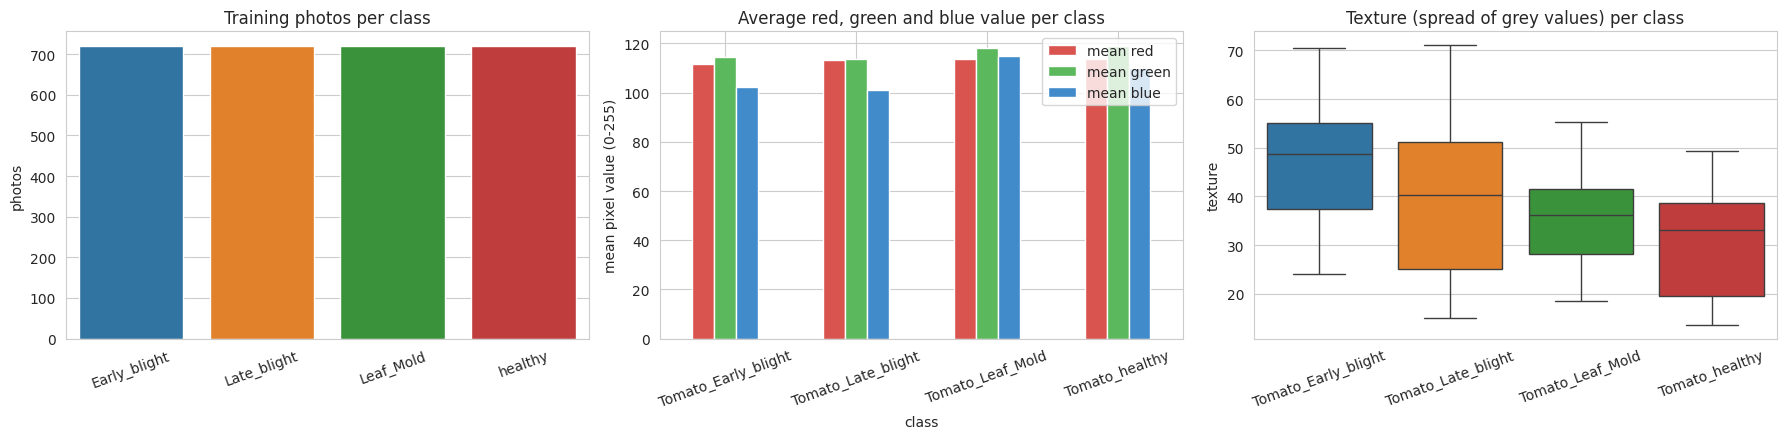

,mean red,mean green,mean blue,brightness,texture
class,,,,,
Tomato_Early_blight,112.699997,113.599998,102.699997,111.500000,48.799999
Tomato_Late_blight,118.500000,118.900002,109.300003,119.800003,40.200001
Tomato_Leaf_Mold,117.400002,119.099998,112.900002,116.900002,36.299999
Tomato_healthy,113.900002,120.099998,110.800003,117.300003,33.099998


In [10]:
exploration_rows = []
sampler = random.Random(RANDOM_SEED)
training_items_for_exploration = labelled_items(SPLIT_FOLDERS["train"], CLASS_NAMES)
for class_index, class_name in enumerate(CLASS_NAMES):
    class_photo_paths = [path for path, label in training_items_for_exploration if label == class_index]
    for photo_path in sampler.sample(class_photo_paths, min(100, len(class_photo_paths))):
        photo = Image.open(photo_path).convert("RGB").resize((128, 128))
        colour_values = np.asarray(photo, dtype=np.float32)
        grey_values = np.asarray(photo.convert("L"), dtype=np.float32)
        exploration_rows.append({"class": class_name, "mean red": colour_values[..., 0].mean(),
                                 "mean green": colour_values[..., 1].mean(), "mean blue": colour_values[..., 2].mean(),
                                 "brightness": grey_values.mean(), "texture": grey_values.std()})
exploration_table = pd.DataFrame(exploration_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
training_counts_per_class = count_per_class(training_items_for_exploration, NUMBER_OF_CLASSES)
short_class_names = [name.replace("Tomato_", "") for name in CLASS_NAMES]
sns.barplot(x=short_class_names, y=training_counts_per_class, ax=axes[0], hue=short_class_names, legend=False)
axes[0].set_title("Training photos per class"); axes[0].set_ylabel("photos")
exploration_table.groupby("class")[["mean red", "mean green", "mean blue"]].mean().reindex(CLASS_NAMES).plot(
    kind="bar", ax=axes[1], color=["#d9534f", "#5cb85c", "#428bca"])
axes[1].set_title("Average red, green and blue value per class"); axes[1].set_ylabel("mean pixel value (0-255)")
sns.boxplot(data=exploration_table, x="class", y="texture", hue="class", legend=False, ax=axes[2], order=CLASS_NAMES)
axes[2].set_title("Texture (spread of grey values) per class"); axes[2].set_xlabel("")
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
display(exploration_table.groupby("class")[["mean red", "mean green", "mean blue", "brightness", "texture"]]
        .median().reindex(CLASS_NAMES).round(1))

## 5. Datasets and class weights

The training photos are shuffled and augmented (flips, rotation, zoom and brightness). The validation and test photos are not augmented. The class weights are computed from the training counts and used in the loss.

In [11]:
training_items, validation_items = split_train_validation(
    labelled_items(SPLIT_FOLDERS["train"], CLASS_NAMES), SPLIT_FOLDERS["train"], VALIDATION_FRACTION)
test_items = labelled_items(SPLIT_FOLDERS["test"], CLASS_NAMES)

split_size_table = pd.DataFrame({
    "training photos": count_per_class(training_items, NUMBER_OF_CLASSES),
    "validation photos": count_per_class(validation_items, NUMBER_OF_CLASSES),
    "test photos": count_per_class(test_items, NUMBER_OF_CLASSES)}, index=CLASS_NAMES)
display(split_size_table)

training_dataset = make_dataset(training_items, NUMBER_OF_CLASSES, shuffle=True, augment=True, batch_size=BATCH_SIZE)
validation_dataset = make_dataset(validation_items, NUMBER_OF_CLASSES, batch_size=BATCH_SIZE)
training_eval_dataset = make_dataset(training_items, NUMBER_OF_CLASSES, batch_size=BATCH_SIZE)
test_dataset = make_dataset(test_items, NUMBER_OF_CLASSES, batch_size=BATCH_SIZE)

training_labels = np.array([label for _, label in training_items])
validation_labels = np.array([label for _, label in validation_items])
test_labels = np.array([label for _, label in test_items])

first_batch_images, first_batch_labels = next(iter(training_dataset))
print("batch of images:", first_batch_images.shape, "| labels:", first_batch_labels.shape,
      "| pixel range:", float(tf.reduce_min(first_batch_images)), "to", float(tf.reduce_max(first_batch_images)))

# Check: the training pipeline and the function the web app uses give the same model input for the same photos.
sample_items = training_items[:5]
input_from_training_pipeline = next(iter(make_dataset(sample_items, NUMBER_OF_CLASSES, batch_size=5)))[0].numpy()
input_from_serving_function = np.concatenate([preprocess_path(path) for path, _ in sample_items])
largest_difference = np.abs(input_from_training_pipeline - input_from_serving_function).max()
print("largest difference between training and serving inputs:", largest_difference)
assert largest_difference < 1e-3, "training and serving preprocessing disagree"

CLASS_WEIGHTS = balanced_class_weights(count_per_class(training_items + validation_items, NUMBER_OF_CLASSES))
class_weight_table = pd.DataFrame({"training photos": count_per_class(training_items + validation_items, NUMBER_OF_CLASSES),
                                   "class weight": np.round(CLASS_WEIGHTS, 4)}, index=CLASS_NAMES)
display(class_weight_table)

,training photos,validation photos,test photos
Tomato_Early_blight,578,142,180
Tomato_Late_blight,580,140,180
Tomato_Leaf_Mold,563,157,180
Tomato_healthy,567,153,180


batch of images: (32, 224, 224, 3) | labels: (32, 4) | pixel range: 0.0 to 253.87619018554688
largest difference between training and serving inputs: 3.0517578e-05


,training photos,class weight
Tomato_Early_blight,720,1.0
Tomato_Late_blight,720,1.0
Tomato_Leaf_Mold,720,1.0
Tomato_healthy,720,1.0


In [12]:
# Check the loss: with weights [2, 1, 1, 1], a photo of class 0 has its loss doubled, a photo of class 1 is unchanged.
demo_true_one_hot = tf.one_hot([0, 1], 4)
demo_probabilities = tf.constant([[0.7, 0.1, 0.1, 0.1], [0.2, 0.5, 0.2, 0.1]])
plain_loss = tf.keras.losses.categorical_crossentropy(demo_true_one_hot, demo_probabilities)
weighted_loss = weighted_categorical_crossentropy([2.0, 1.0, 1.0, 1.0])(demo_true_one_hot, demo_probabilities)
print("plain cross-entropy:", plain_loss.numpy().round(4), "| weighted:", weighted_loss.numpy().round(4))

plain cross-entropy: [0.3567 0.6931] | weighted: [0.7133 0.6931]


## 6. The model

- **Base:** MobileNetV2 with ImageNet weights, without its original 1000-class output. The base is **frozen**, so its weights do not change, and its BatchNorm layers run in inference mode.
- **Head (trained):** global average pooling (1 280 features per photo), dropout 0.3, a dense layer of 128 units with L2 weight decay, dropout 0.3, and a dense softmax layer for the four classes with L2 weight decay.

In [13]:
model = build_model(NUMBER_OF_CLASSES, dropout_rate=DROPOUT_RATE, l2_strength=L2_STRENGTH,
                    learning_rate=LEARNING_RATE, class_weights=CLASS_WEIGHTS, hidden_units=HIDDEN_UNITS)
total_parameters = model.count_params()
trainable_parameters = sum(int(np.prod(weight.shape)) for weight in model.trainable_weights)
print(f"total parameters: {total_parameters:,} | trainable (head only): {trainable_parameters:,} "
      f"({trainable_parameters / total_parameters:.1%})")
model.summary(expand_nested=False)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
total parameters: 2,422,468 | trainable (head only): 164,484 (6.8%)


Model: "tomato_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_base (Functional)   │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Training

Training runs for up to 30 epochs with these callbacks:

- **Early stopping** on validation loss: stops when the loss has not dropped by at least 0.002 for 5 epochs, and restores the best epoch's weights.
- **Reduce learning rate on plateau** on validation loss: halves the learning rate after 3 epochs without improvement.
- **Model checkpoint:** saves the best epoch (lowest validation loss) to disk.
- **TensorBoard:** logs every metric for every epoch. Open it with the command below the training cell.
- **Epoch metrics:** after every epoch, precision, recall, F1 score and ROC AUC are measured on the training photos and on the validation photos, and printed.

The training photos are measured without augmentation, in inference mode, so the training metrics are not distorted by the random changes.

In [14]:
RUN_NAME = datetime.now().strftime("%Y%m%d-%H%M%S")
BEST_MODEL_PATH = f"{MODEL_DIR}/tomato_mobilenetv2_best.keras"
TENSORBOARD_LOG_FOLDER = f"{RESULTS_DIR}/tensorboard_logs/{RUN_NAME}"

epoch_metrics_callback = EpochMetrics(training_eval_dataset, training_labels,
                                      validation_dataset, validation_labels, CLASS_WEIGHTS)
training_callbacks = [
    epoch_metrics_callback,      # runs first, so TensorBoard also receives its precision, recall, F1 and ROC AUC
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", min_delta=EARLY_STOPPING_MIN_DELTA,
                                     patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=REDUCE_LR_FACTOR,
                                         patience=REDUCE_LR_PATIENCE, min_lr=MINIMUM_LEARNING_RATE, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(BEST_MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=1),
    tf.keras.callbacks.TensorBoard(log_dir=TENSORBOARD_LOG_FOLDER, histogram_freq=0),
]

training_run = model.fit(training_dataset, validation_data=validation_dataset, epochs=EPOCHS,
                         callbacks=training_callbacks, verbose=0, shuffle=False)
TRAINING_HISTORY = pd.DataFrame(epoch_metrics_callback.history_rows)
epochs_trained = len(TRAINING_HISTORY)
best_epoch = int(TRAINING_HISTORY.loc[TRAINING_HISTORY["val_loss"].idxmin(), "epoch"])
print(f"training stopped after {epochs_trained} epochs; the kept weights are from epoch {best_epoch}")
print("TensorBoard: run  %tensorboard --logdir " + f"{RESULTS_DIR}/tensorboard_logs" + "  in a cell (Colab or Jupyter)")

epoch  1 | training: loss 0.859  accuracy 0.666  precision 0.853  recall 0.843  f1 score 0.839  roc auc 0.970 | validation: loss 0.443  accuracy 0.836  precision 0.853  recall 0.830  f1 score 0.831  roc auc 0.973

Epoch 1: val_loss improved from None to 0.44342, saving model to /content/drive/MyDrive/tomato_leaf_project/models/tomato_mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/tomato_leaf_project/models/tomato_mobilenetv2_best.keras
epoch  2 | training: loss 0.517  accuracy 0.811  precision 0.882  recall 0.880  f1 score 0.877  roc auc 0.981 | validation: loss 0.364  accuracy 0.872  precision 0.879  recall 0.867  f1 score 0.867  roc auc 0.980

Epoch 2: val_loss improved from 0.44342 to 0.36372, saving model to /content/drive/MyDrive/tomato_leaf_project/models/tomato_mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/tomato_leaf_project/models/tomato_mobilenetv2_best.keras
epoch  3 | training: loss 0.450  accuracy 0.841  

,epoch,loss,accuracy,precision,recall,f1 score,roc auc,validation loss,validation accuracy,validation precision,validation recall,validation f1 score,validation roc auc
0,1,0.8592,0.6661,0.8527,0.8433,0.8391,0.9699,0.4434,0.8361,0.8528,0.8295,0.8307,0.9732
1,2,0.5167,0.8108,0.8822,0.8801,0.8770,0.9805,0.3637,0.8716,0.8786,0.8670,0.8671,0.9801
2,3,0.4496,0.8409,0.9044,0.9034,0.9015,0.9848,0.3130,0.8970,0.8981,0.8936,0.8935,0.9841
3,4,0.4050,0.8505,0.8963,0.8939,0.8908,0.9854,0.3159,0.8936,0.8990,0.8898,0.8891,0.9855
4,5,0.3784,0.8588,0.9149,0.9139,0.9117,0.9873,0.3047,0.8885,0.8916,0.8842,0.8839,0.9853
5,6,0.3625,0.8763,0.9100,0.9100,0.9079,0.9876,0.3052,0.8868,0.8893,0.8831,0.8836,0.9858
6,7,0.3312,0.8877,0.9262,0.9268,0.9258,0.9914,0.2532,0.9155,0.9158,0.9128,0.9135,0.9896
7,8,0.3441,0.8833,0.9188,0.9189,0.9174,0.9900,0.2725,0.9172,0.9172,0.9154,0.9147,0.9885
8,9,0.3297,0.8877,0.9333,0.9329,0.9317,0.9927,0.2499,0.9206,0.9228,0.9182,0.9179,0.9914
9,10,0.3260,0.8868,0.9291,0.9294,0.9283,0.9913,0.2574,0.9139,0.9127,0.9120,0.9119,0.9899


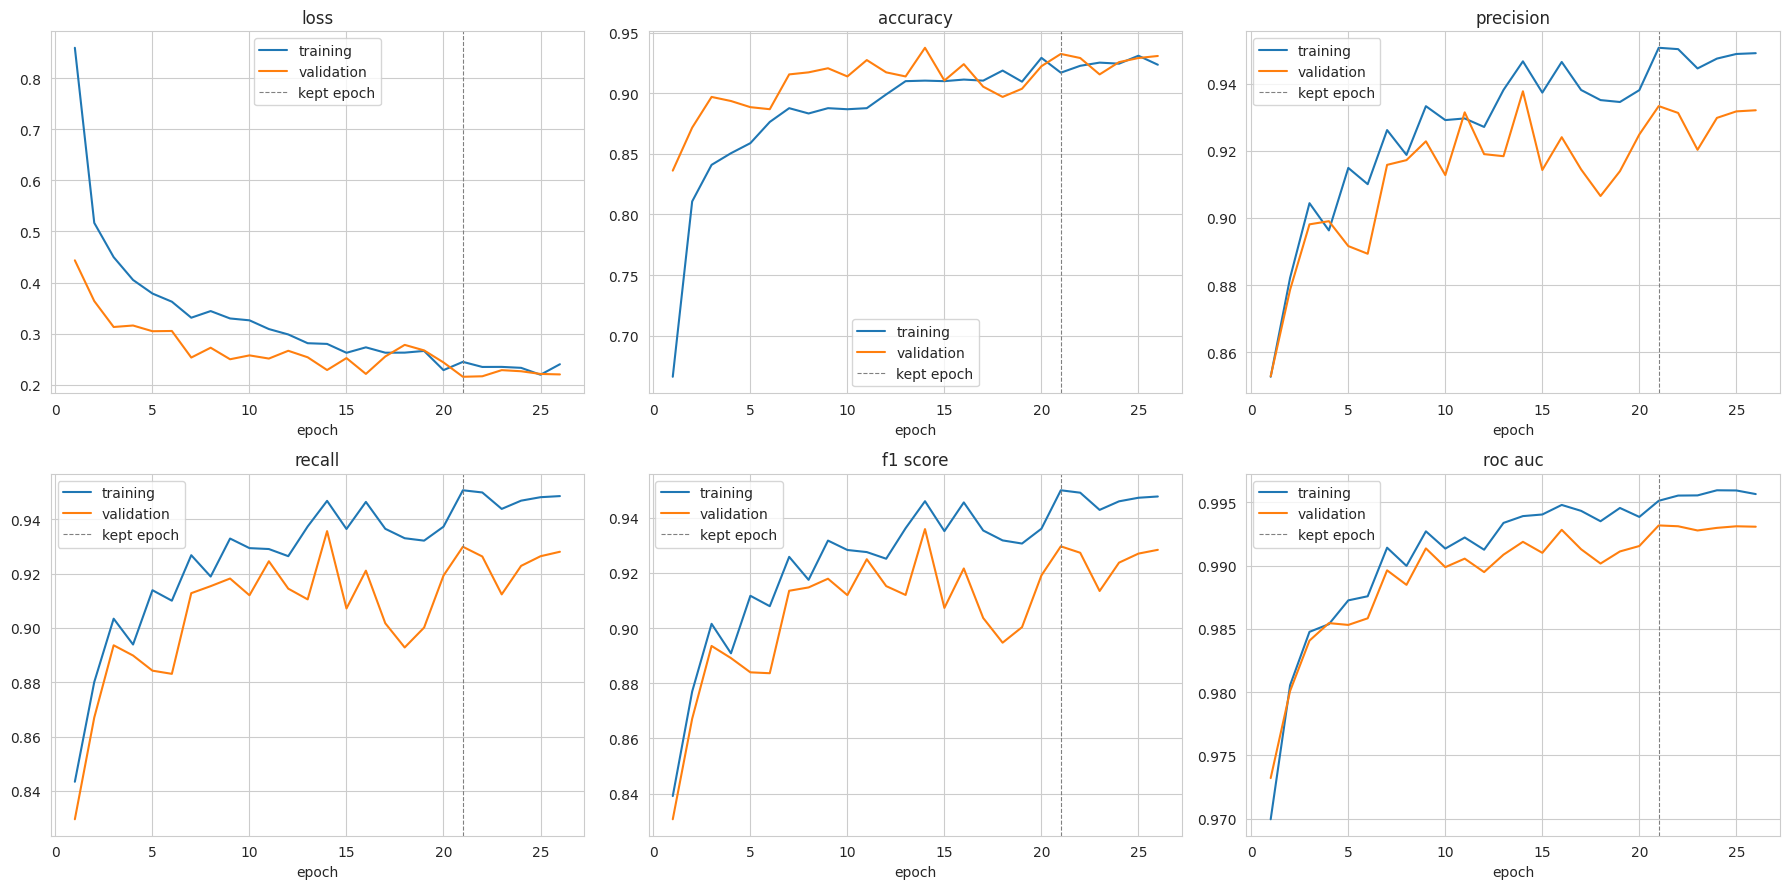

In [15]:
def readable_name(column_name):
    # "val_f1_score" -> "validation f1 score", "f1_score" -> "f1 score"
    return column_name.replace("val_", "validation ").replace("_", " ")

history_for_display = TRAINING_HISTORY.rename(columns=readable_name)
display(history_for_display.round(4))

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
metric_panels = [("loss", "loss"), ("accuracy", "accuracy"), ("precision", "precision"),
                 ("recall", "recall"), ("f1_score", "f1 score"), ("roc_auc", "roc auc")]
for axis, (metric_key, metric_title) in zip(axes.ravel(), metric_panels):
    axis.plot(TRAINING_HISTORY["epoch"], TRAINING_HISTORY[metric_key], label="training")
    axis.plot(TRAINING_HISTORY["epoch"], TRAINING_HISTORY[f"val_{metric_key}"], label="validation")
    axis.axvline(best_epoch, color="grey", linestyle="--", linewidth=0.8, label="kept epoch")
    axis.set_title(metric_title); axis.set_xlabel("epoch"); axis.legend()
plt.tight_layout(); plt.show()

## 8. Results on the test set

The final model (the kept epoch) is evaluated on the **test set**: 180 photos per class that were never used for training, validation or tuning. The results are reported overall, for each class, and as confusion matrices.

In [16]:
test_probabilities = model.predict(test_dataset, verbose=0)
test_predicted_labels = test_probabilities.argmax(axis=1)

overall_scores = compute_metrics(test_labels, test_probabilities, CLASS_WEIGHTS)
overall_results_table = pd.DataFrame([{
    "accuracy": overall_scores["accuracy"],
    "loss": overall_scores["loss"],
    "precision": overall_scores["precision"],
    "recall": overall_scores["recall"],
    "f1 score": overall_scores["f1"],
    "roc auc": overall_scores["roc_auc"]}], index=["test set (all four classes)"])
print("OVERALL RESULTS ON THE TEST SET (macro averages, every class counts equally)")
display(overall_results_table.round(4))

OVERALL RESULTS ON THE TEST SET (macro averages, every class counts equally)


,accuracy,loss,precision,recall,f1 score,roc auc
test set (all four classes),0.9431,0.1847,0.9431,0.9431,0.9426,0.9933


In [17]:
per_class_rows = compute_per_class_metrics(test_labels, test_probabilities, CLASS_NAMES)
per_class_results_table = pd.DataFrame(per_class_rows).rename(columns={
    "class": "class", "precision": "precision", "recall": "recall", "f1_score": "f1 score",
    "test_photos": "test photos", "roc_auc": "roc auc"}).set_index("class")
print("RESULTS FOR EACH CLASS ON THE TEST SET")
display(per_class_results_table.round(4))

print("Detailed report (precision, recall, f1-score and support for each class):")
print(classification_report(test_labels, test_predicted_labels, target_names=CLASS_NAMES, digits=3))

RESULTS FOR EACH CLASS ON THE TEST SET


,precision,recall,f1 score,test photos,roc auc
class,,,,,
Tomato_Early_blight,0.9419,0.9000,0.9205,180,0.9912
Tomato_Late_blight,0.9477,0.9056,0.9261,180,0.9861
Tomato_Leaf_Mold,0.9405,0.9667,0.9534,180,0.9958
Tomato_healthy,0.9424,1.0000,0.9704,180,0.9999


Detailed report (precision, recall, f1-score and support for each class):
                     precision    recall  f1-score   support

Tomato_Early_blight      0.942     0.900     0.920       180
 Tomato_Late_blight      0.948     0.906     0.926       180
   Tomato_Leaf_Mold      0.941     0.967     0.953       180
     Tomato_healthy      0.942     1.000     0.970       180

           accuracy                          0.943       720
          macro avg      0.943     0.943     0.943       720
       weighted avg      0.943     0.943     0.943       720



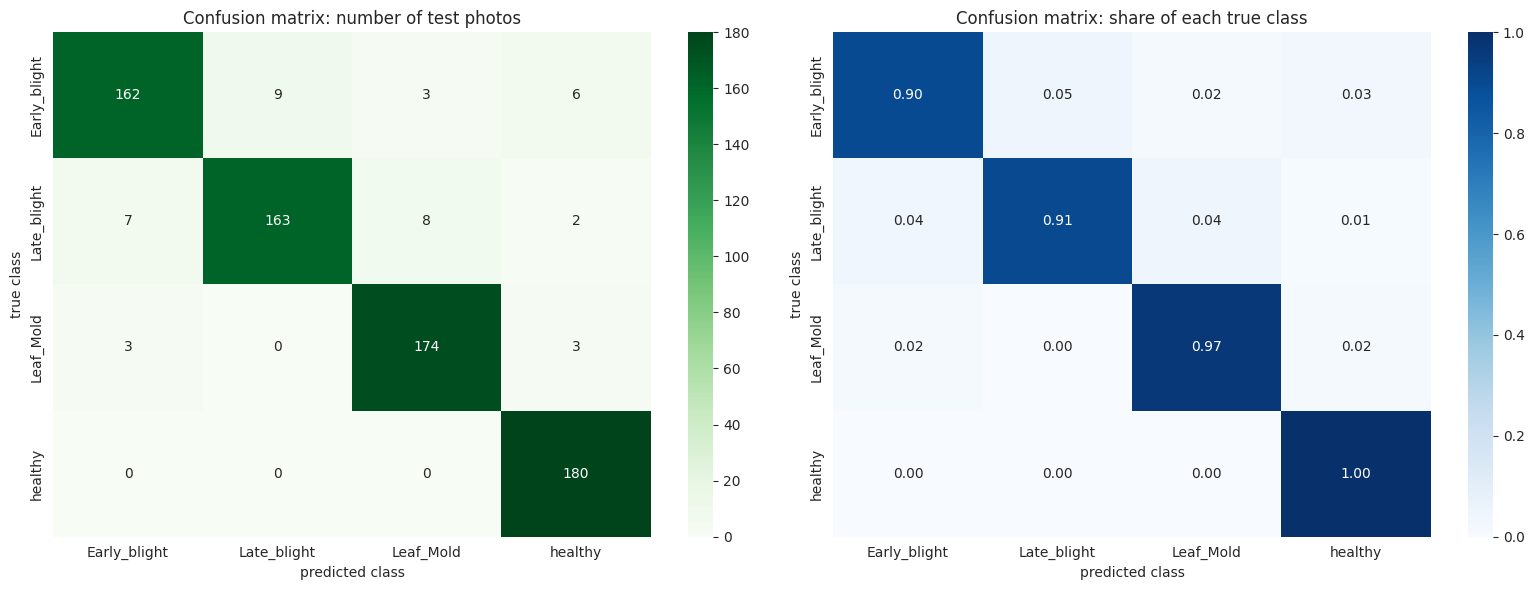

In [18]:
short_class_names = [name.replace("Tomato_", "") for name in CLASS_NAMES]
counts_matrix = confusion_matrix(test_labels, test_predicted_labels)
shares_matrix = counts_matrix / counts_matrix.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(counts_matrix, annot=True, fmt="d", cmap="Greens", ax=axes[0],
            xticklabels=short_class_names, yticklabels=short_class_names)
axes[0].set_title("Confusion matrix: number of test photos"); axes[0].set_xlabel("predicted class"); axes[0].set_ylabel("true class")
sns.heatmap(shares_matrix, annot=True, fmt=".2f", cmap="Blues", ax=axes[1], vmin=0, vmax=1,
            xticklabels=short_class_names, yticklabels=short_class_names)
axes[1].set_title("Confusion matrix: share of each true class"); axes[1].set_xlabel("predicted class"); axes[1].set_ylabel("true class")
plt.tight_layout(); plt.show()

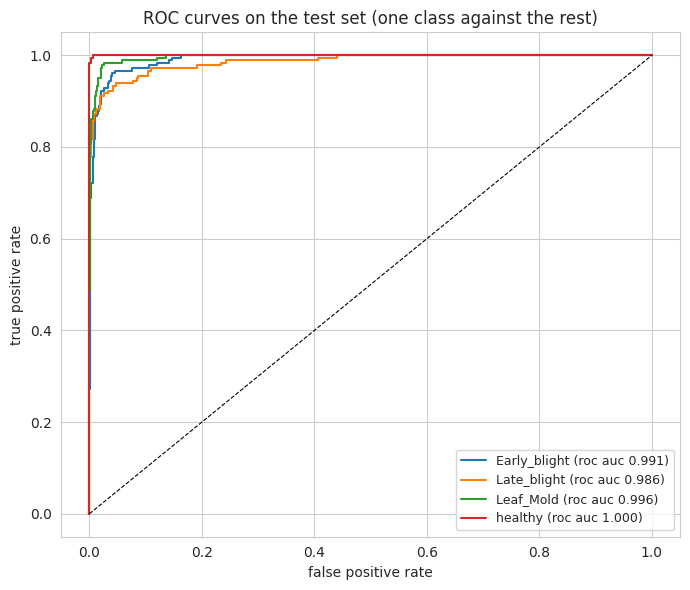

In [19]:
plt.figure(figsize=(7, 6))
for class_index, class_name in enumerate(CLASS_NAMES):
    false_positive_rate, true_positive_rate, _ = roc_curve((test_labels == class_index).astype(int),
                                                           test_probabilities[:, class_index])
    plt.plot(false_positive_rate, true_positive_rate,
             label=f"{class_name.replace('Tomato_', '')} (roc auc {auc(false_positive_rate, true_positive_rate):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
plt.title("ROC curves on the test set (one class against the rest)")
plt.legend(fontsize=9); plt.tight_layout(); plt.show()

## 9. Explaining the decisions with Grad-CAM

Grad-CAM shows which part of a photo pushed the model's score for a class up. It uses the gradients of the class score with respect to the last convolution layer of MobileNetV2, averages them per channel, and combines the channels into a heat map. Red regions matter most for the predicted class.

Twelve test photos are explained: three per class, chosen at random with the fixed seed. The title of each photo gives the true class, the predicted class and the model's confidence.

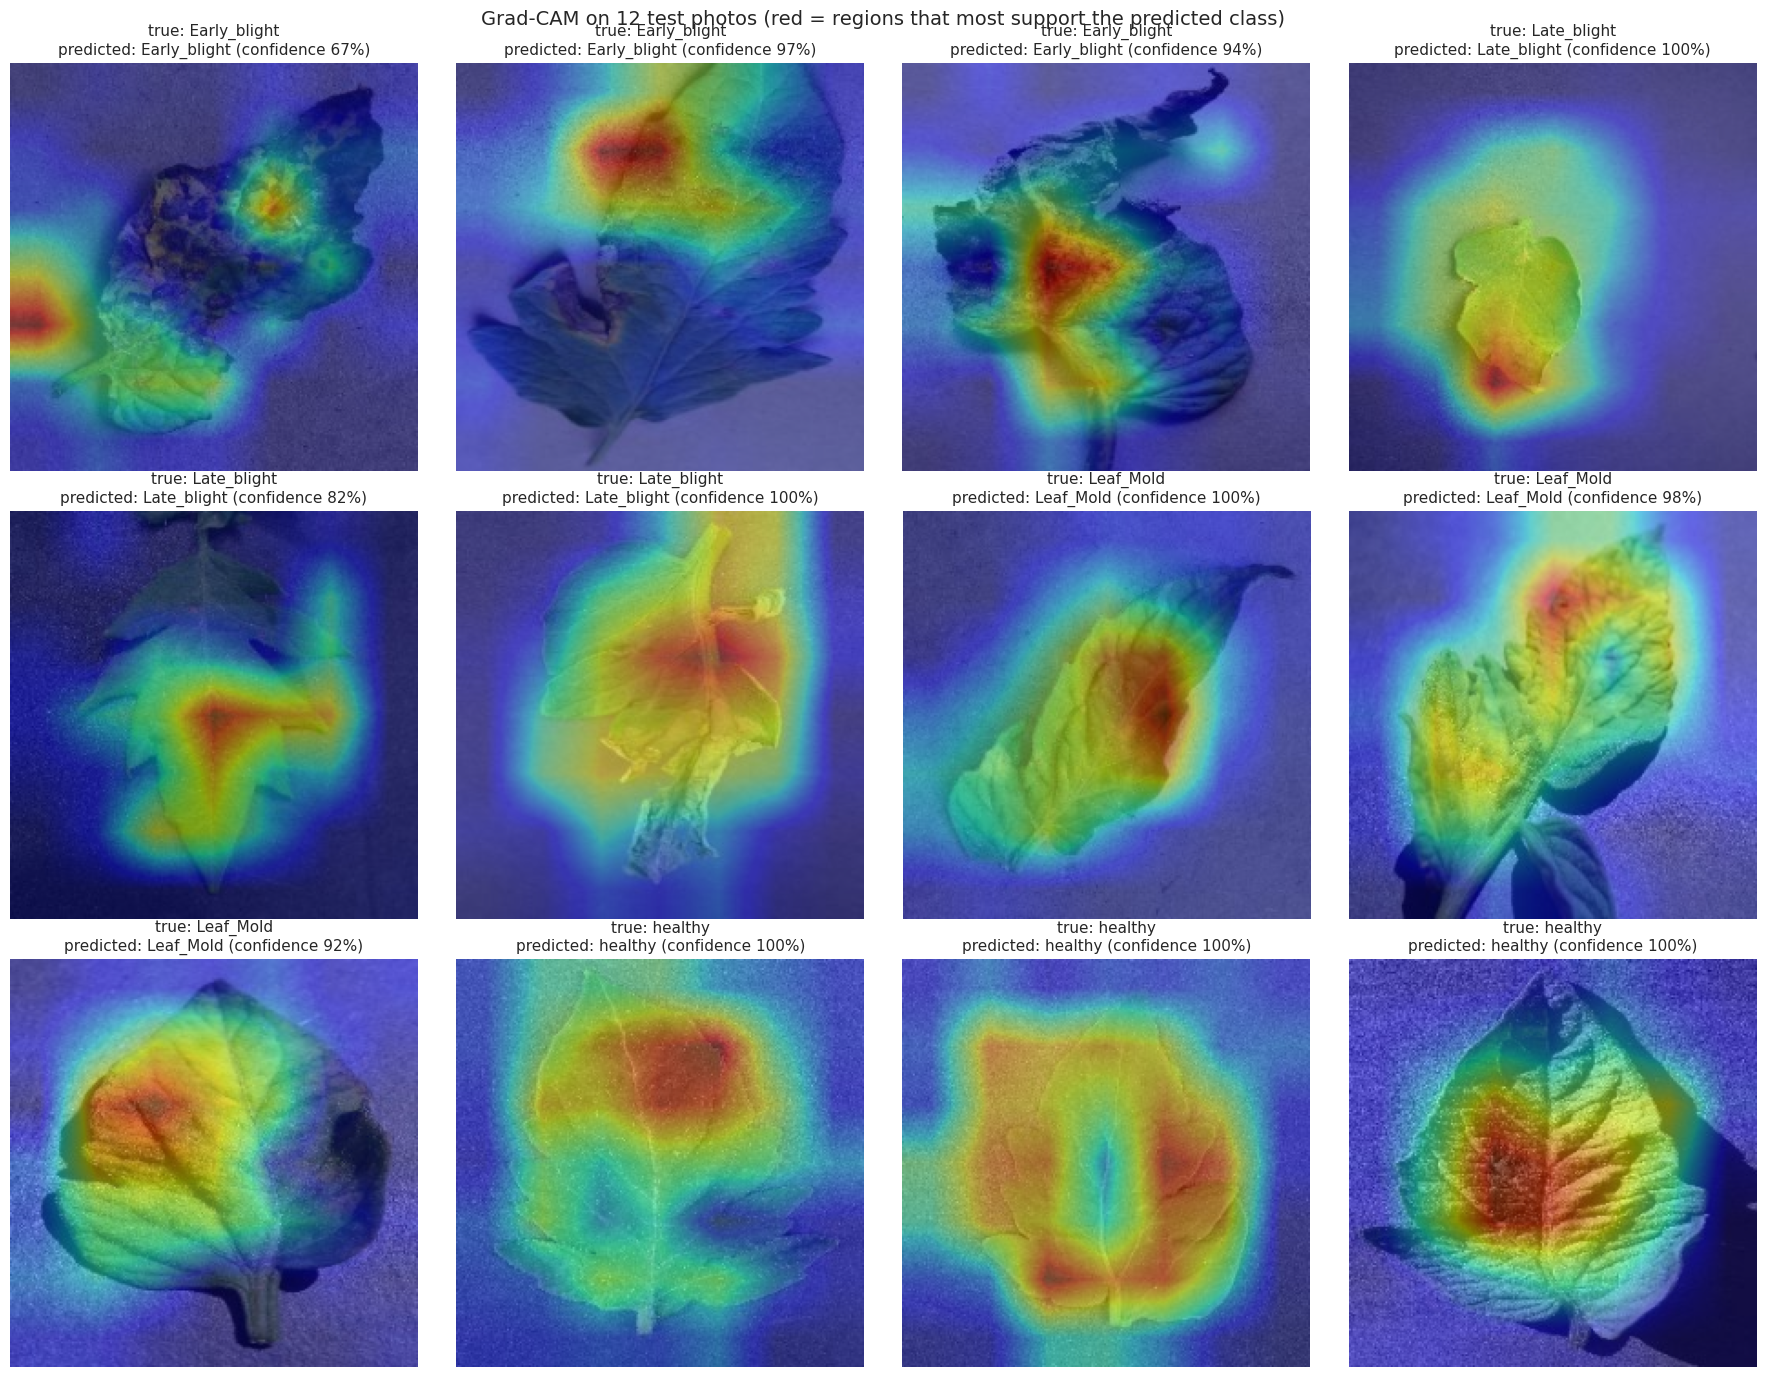

In [20]:
def make_gradcam_heatmap(classifier, photo_batch, class_index):
    # Grad-CAM for one photo: the regions of the last convolution layer that raise the score of class_index.
    base_model = classifier.get_layer(BASE_MODEL_NAME)
    last_convolution_output = base_model.get_layer("out_relu").output     # last convolution block of MobileNetV2
    feature_extractor = tf.keras.Model(base_model.input, last_convolution_output)
    base_position = classifier.layers.index(base_model)
    rescaling_layer = classifier.layers[base_position - 1]
    head_layers = classifier.layers[base_position + 1:]                  # pooling, dropout, dense, dropout, dense

    with tf.GradientTape() as gradient_tape:
        rescaled_photos = rescaling_layer(photo_batch)
        convolution_maps = feature_extractor(rescaled_photos)
        gradient_tape.watch(convolution_maps)
        head_output = convolution_maps
        for layer in head_layers:
            head_output = layer(head_output, training=False)
        class_score = head_output[:, class_index]

    gradients = gradient_tape.gradient(class_score, convolution_maps)
    channel_importance = tf.reduce_mean(gradients, axis=(1, 2))           # one weight per channel
    weighted_maps = tf.reduce_sum(convolution_maps * channel_importance[:, None, None, :], axis=-1)
    heatmap = tf.nn.relu(weighted_maps)[0]
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)                  # scale to 0-1
    heatmap = tf.image.resize(heatmap[..., None], IMG_SIZE)[..., 0].numpy()
    return heatmap, head_output.numpy()[0]

rng_for_gradcam = random.Random(RANDOM_SEED)
gradcam_test_items = []
for class_index in range(NUMBER_OF_CLASSES):
    class_test_items = [item for item in test_items if item[1] == class_index]
    gradcam_test_items.extend(rng_for_gradcam.sample(class_test_items, GRADCAM_PHOTOS_PER_CLASS))

figure, axes = plt.subplots(3, 4, figsize=(18, 14))
for axis, (photo_path, true_class_index) in zip(axes.ravel(), gradcam_test_items):
    photo_batch = preprocess_path(photo_path)                            # 0-255 pixels, the model's input
    class_probabilities = model.predict(photo_batch, verbose=0)[0]
    predicted_class_index = int(np.argmax(class_probabilities))
    heatmap, _ = make_gradcam_heatmap(model, photo_batch, predicted_class_index)
    displayed_photo = photo_batch[0].astype("uint8")
    coloured_heatmap = colour_maps.jet(heatmap)[..., :3]
    overlay = np.clip(0.55 * displayed_photo / 255.0 + 0.45 * coloured_heatmap, 0, 1)
    axis.imshow(overlay)
    axis.set_title(f"true: {CLASS_NAMES[true_class_index].replace('Tomato_', '')}\n"
                   f"predicted: {CLASS_NAMES[predicted_class_index].replace('Tomato_', '')} "
                   f"(confidence {class_probabilities[predicted_class_index]:.0%})", fontsize=11)
    axis.axis("off")
plt.suptitle("Grad-CAM on 12 test photos (red = regions that most support the predicted class)", fontsize=14)
plt.tight_layout(); plt.show()

## 10. Saving the model and the results

The files the web application needs are the final model (`tomato_mobilenetv2.keras`), the class order, the class weights and the overall test metrics. The notebook also saves the training history, the test results and the split, for the report.

In [21]:
FINAL_MODEL_PATH = f"{MODEL_DIR}/tomato_mobilenetv2.keras"
model.save(FINAL_MODEL_PATH)
with open(f"{MODEL_DIR}/class_names.json", "w") as class_file:
    json.dump(CLASS_NAMES, class_file)
with open(f"{MODEL_DIR}/class_weights.json", "w") as weights_file:
    json.dump(dict(zip(CLASS_NAMES, CLASS_WEIGHTS)), weights_file, indent=2)
with open(f"{MODEL_DIR}/metrics.json", "w") as metrics_file:
    json.dump({key: (None if value is None else round(float(value), 4)) for key, value in overall_scores.items()},
              metrics_file, indent=2)

TRAINING_HISTORY.to_csv(f"{RESULTS_DIR}/training_history.csv", index=False)
overall_results_table.to_csv(f"{RESULTS_DIR}/test_results_overall.csv")
per_class_results_table.to_csv(f"{RESULTS_DIR}/test_results_per_class.csv")
shutil.copy(SPLIT_MANIFEST_PATH, f"{RESULTS_DIR}/splits.csv")

# Reload the saved file and check that it predicts the same as the trained model.
reloaded_model = load_trained(FINAL_MODEL_PATH)
check_photos = np.concatenate([preprocess_path(path) for path, _ in test_items[:6]])
print("reloaded model gives the same predictions:",
      np.allclose(model.predict(check_photos, verbose=0), reloaded_model.predict(check_photos, verbose=0), atol=1e-5))
print("saved to:", sorted(os.listdir(MODEL_DIR)))

reloaded model gives the same predictions: True
saved to: ['class_names.json', 'class_weights.json', 'metrics.json', 'tomato_mobilenetv2.keras', 'tomato_mobilenetv2_best.keras']


## 11. Conclusion

The notebook trains a classifier head on a frozen ImageNet MobileNetV2 with a class-weighted loss, using one run with the configuration in the table at the top. The per-epoch precision, recall, F1 score and ROC AUC (training and validation) show how training progressed, and the test results give the final, unseen scores, overall and for each class. The confusion matrices show which classes are confused, and Grad-CAM shows the regions the model used.

**Before reporting the numbers**, check two things: the duplicate check in section 3 (how many test photos have a near copy in training, since that would make the test score optimistic), and the training curves in section 7 (a large gap between the training and validation curves means overfitting).

**To use the model in the web app**, copy `models/tomato_mobilenetv2.keras`, `class_names.json`, `class_weights.json` and `metrics.json` into the repository's `models/` folder.